# PRÁCTICA 6 – "Detección de Bordes”

**Objetivo**: implementación y aplicación de distintos detectores de borde


In [4]:
import numpy as np
import cv2 
import matplotlib.pyplot as plt

## PRIMERA PARTE: Generación de imágenes. Análisis de perfiles de intensidad

1. A partir de la lectura de la imagen “img.png”, genera las siguientes imágenes:

- Imagen de intensidad I.

- Imagen de intensidad suavizada Igauss: imagen resultado de aplicar a I un filtro gaussiano 5x5 y desviación típica 1.4.

In [5]:
# Imagen de intensidad I
I = cv2.imread("imagenEntrada/img.png")
I = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

# Imagen de intensidad suavizada Igauss
Igauss = cv2.GaussianBlur(I, (5,5), 1.4, borderType=cv2.BORDER_REPLICATE)

print(I.shape)
print(Igauss.shape)

(188, 635)
(188, 635)


2. En dos ventanas, una para cada una de las dos imágenes anteriores, representa:

- En una gráfica superior: la imagen de intensidad con las siguientes líneas horizontales
representadas sobre la imagen, cada una de un color y dadas por las filas: int(0.25xN),
int(0.5xN) y int(0.75xN), siendo N el número de filas de la imagen

-  En una gráfica inferior: los perfiles de intensidad correspondientes a las líneas
horizontales anteriores, representados en los mismos colores y con una leyenda que
indique el valor de la fila a la que se corresponde el perfil. 

**Observacion:**

- Los perfiles deben representarse en la misma escala: eje X: desde 0 hasta el número de
columnas de la imagen; eje Y: desde 0 hasta 270.

- Utiliza plt.axhline para representar una determinada línea sobre una imagen.

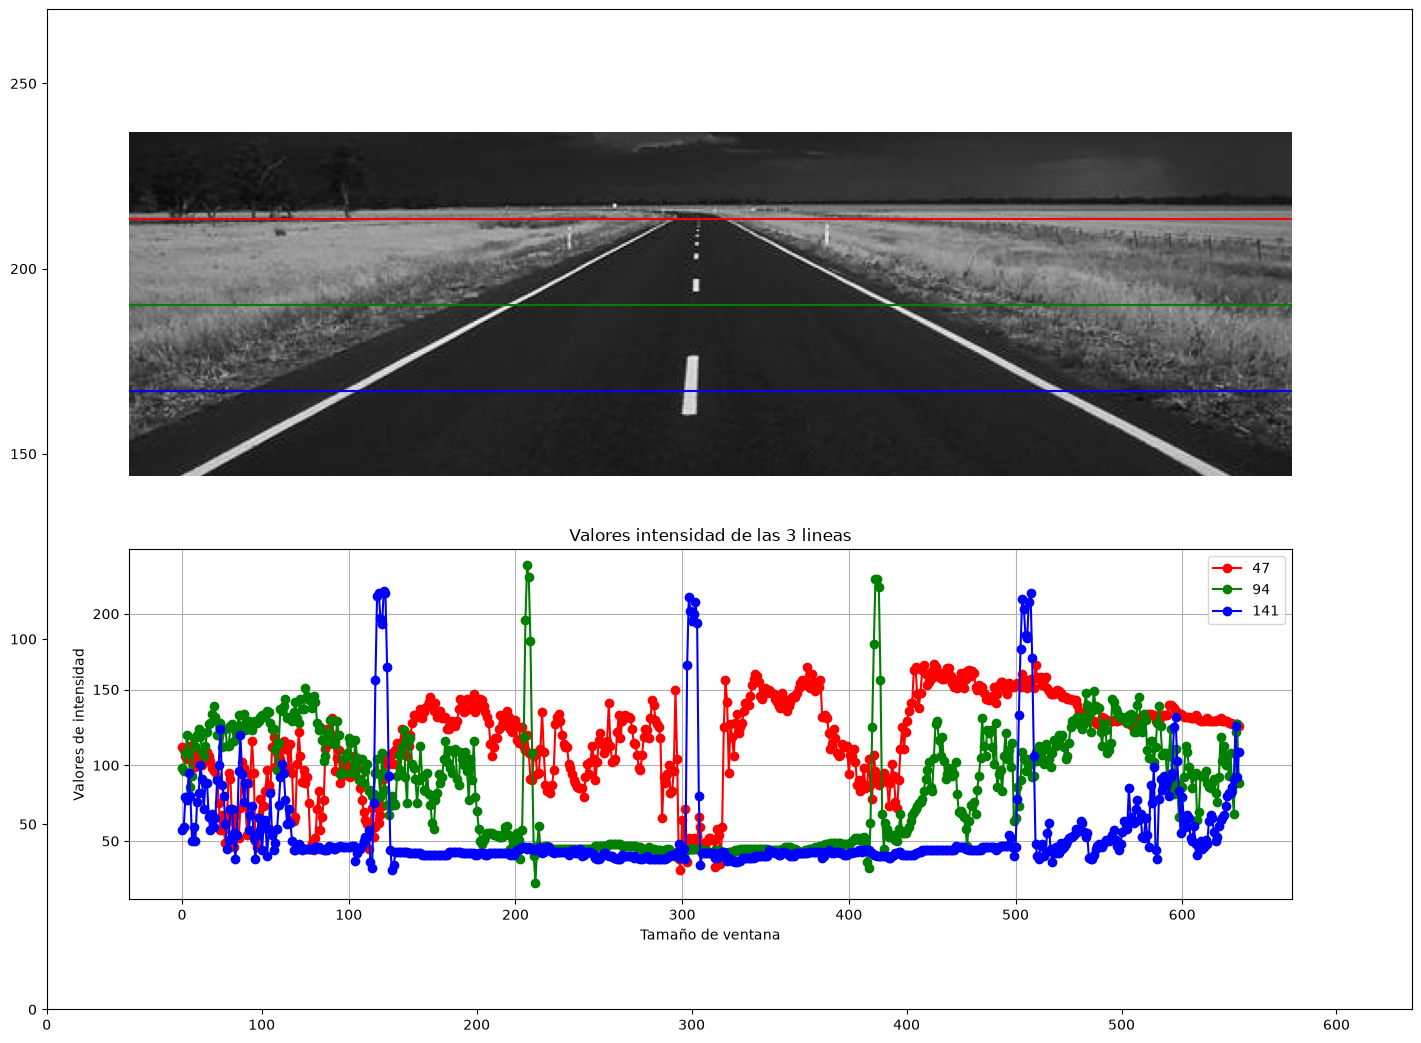

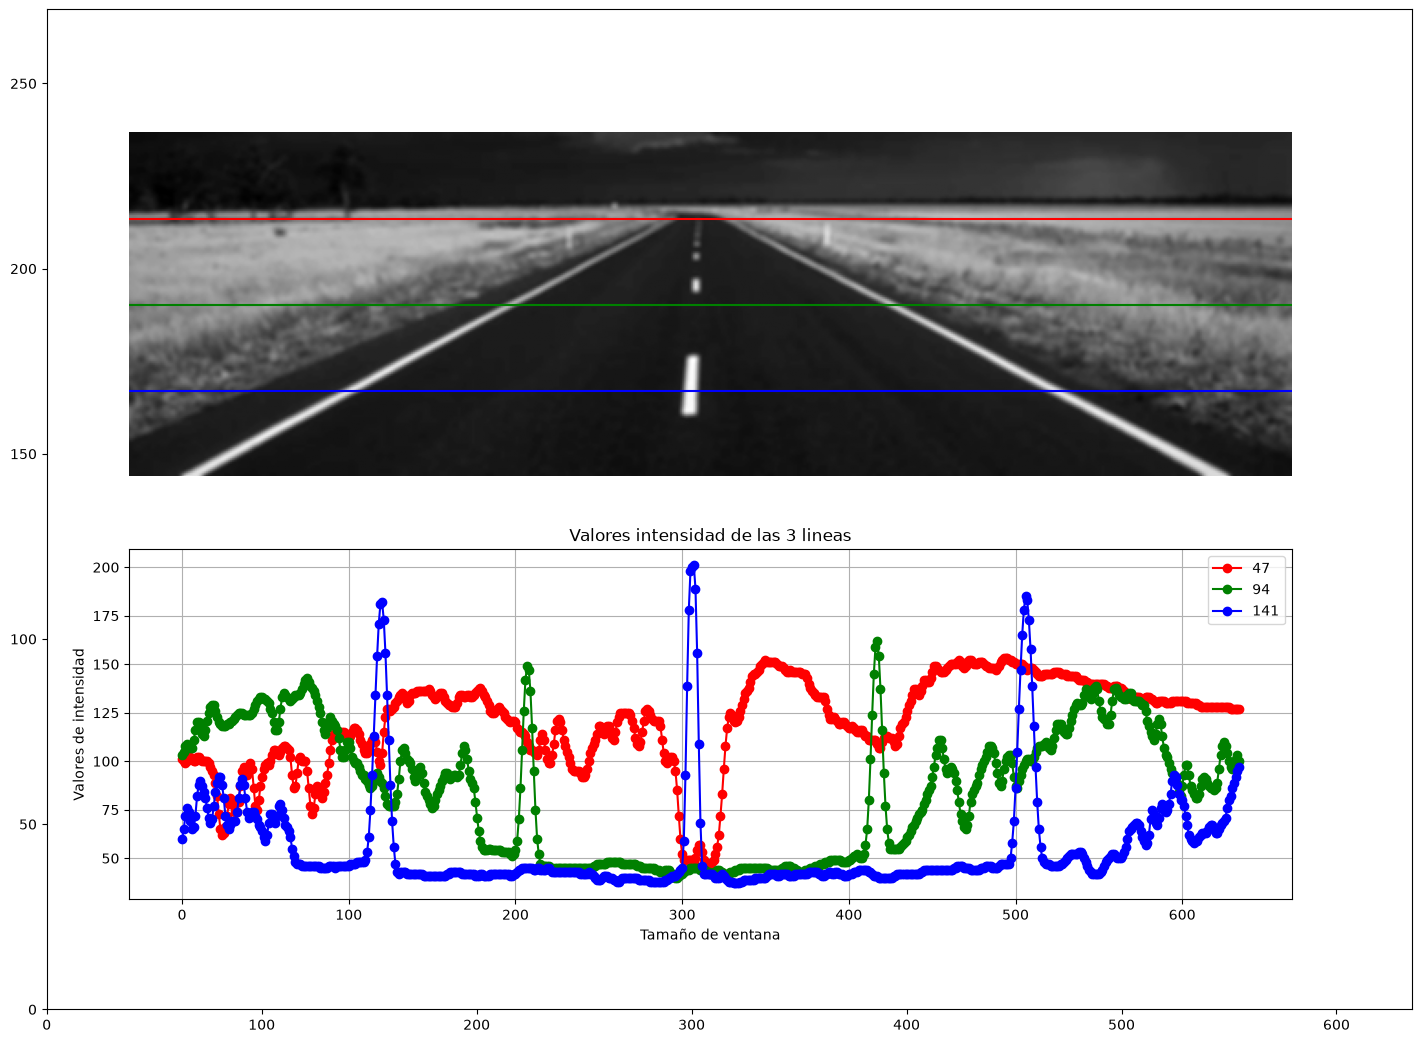

In [19]:
N, M = I.shape

lineas = [int(0.25 * N), int(0.50 * N), int(0.75 * N)]
colores = ["red", "green", "blue"]

ANCHO = 15            
izq, der = 0.07, 0.98
w = der - izq

fig1 = plt.figure(figsize=(15,10))
ax1 = fig1.add_axes([izq,0,w,1])
plt.subplot(2,1,1)
plt.imshow(I, cmap="gray")
for i in range(len(lineas)):
    plt.axhline(y=lineas[i], color=colores[i], linestyle="-", linewidth=1.5)
plt.axis("off")

linea1 = I[lineas[0], :]
linea2 = I[lineas[1], :]
linea3 = I[lineas[2], :]
x = range(M)

plt.subplot(2,1,2)
ax1.set_xlim(0, M)
ax1.set_ylim(0,270)
plt.plot(x, linea1, color="red", marker="o", label=lineas[0])
plt.plot(x, linea2, color="green", marker="o", label=lineas[1])
plt.plot(x, linea3, color="blue", marker="o", label=lineas[2])

plt.xlabel("Tamaño de ventana")
plt.ylabel("Valores de intensidad")
plt.title("Valores intensidad de las 3 lineas")
plt.legend()
plt.grid(True)
plt.show()

fig2 = plt.figure(figsize=(15,10))
ax2 = fig2.add_axes([izq,0,w,1])
plt.subplot(2,1,1)
plt.imshow(Igauss, cmap="gray")
for i in range(len(lineas)):
    plt.axhline(y=lineas[i], color=colores[i], linestyle="-", linewidth=1.5)
plt.axis("off")

linea1 = Igauss[lineas[0], :]
linea2 = Igauss[lineas[1], :]
linea3 = Igauss[lineas[2], :]
x = range(M)

plt.subplot(2,1,2)
ax2.set_xlim(0, M)
ax2.set_ylim(0,270)
plt.plot(x, linea1, color="red", marker="o", label=lineas[0])
plt.plot(x, linea2, color="green", marker="o", label=lineas[1])
plt.plot(x, linea3, color="blue", marker="o", label=lineas[2])

plt.xlabel("Tamaño de ventana")
plt.ylabel("Valores de intensidad")
plt.title("Valores intensidad de las 3 lineas")
plt.legend()
plt.grid(True)
plt.show()



3. **Analiza las representaciones y extrae conclusiones en relación a la caracterización de los
píxeles de borde y los fundamentos metodológicos de los algoritmos empleados en su
detección.**

Cada curva es la intensidad I(i,j) a lo largo de una fila con j recorriendo las columnas. Hay tres objetos reñevamtes en la imagen, el asfalto(valores oscuros), las marcas viales(valores muy claros) y cesped(valores mas intermedios).

Un borde es la discontinuidad local de la intensidad. En la representacion se puede ver como escalones, que serían el cambio de cesped a asfalto. Picos que serian las Marcas blancas sobre el asfalto. Y rampas que serían cambios mas graduales como sombras.

Por ello un pixel de borde no es un pixel con un valor concreto sino un pixel con un gradiente elevado.

Como fundamentos metodológicos de los algoritmos de detección de bordes podemos usar:

- **La primera derivada**, que será maxima en los flancos de los picos de las marcas viales y minima en las mesetas de asfalto.

- **La segunda derivada**, el borde se localizaría en el cruce por cero dando bordes finos y bien localizados pero muy susceptible al ruido.



## SEGUNDA PARTE: Implementación de detector de bordes basado en primera derivada

4. Implementa la siguiente función (almacenada en fichero Python
funcion_calcular_gradiente.py) para calcular los gradientes de una imagen requeridos para
aplicar un detector de bordes basado en primera derivada: 

```Gx, Gy, ModG = calcular_gradiente (I, Hx, Hy)```

Esta función deberá:

- Para cada píxel de la imagen de entrada I, obtener las componentes horizontal y
vertical, Gx y Gy, del vector gradiente calculadas considerando las máscaras de
convolución Hx y Hy respectivamente y considerando padding ‘replicate’.

- Obtener la magnitud del vector gradiente ModG.


In [7]:
def calcular_gradiente(I, Hx, Hy):
    filas, columnas = I.shape
    nx, mx = Hx.shape
    ny, my = Hy.shape

    mitadx = [nx // 2, mx // 2]
    mitady = [ny // 2, my // 2]

    padx = cv2.copyMakeBorder(I, mitadx[0], mitadx[0], mitadx[1], mitadx[1], borderType=cv2.BORDER_REPLICATE)
    pady = cv2.copyMakeBorder(I, mitady[0], mitady[0], mitady[1], mitady[1], borderType=cv2.BORDER_REPLICATE)

    Gx = np.zeros_like(I, dtype=np.float32)
    Gy = np.zeros_like(I, dtype=np.float32)
    ModG = np.zeros_like(I, dtype=np.float32)

    for i in range(filas):
        for j in range(columnas):
            ventanax = padx[i:i+nx, j:j+mx]
            ventanay = pady[i:i+ny, j:j+my]
            Gx[i,j] = np.sum(ventanax.astype(np.float32) * Hx)
            Gy[i,j] = np.sum(ventanay.astype(np.float32) * Hy)

    ModG = np.sqrt(Gx**2 + Gy**2)

    return Gx, Gy, ModG

5. Aplica la función anterior con las máscaras de convolución de Sobel a la imagen de
intensidad I y a la imagen de intensidad suavizada Igauss y visualiza como imágenes la
siguiente información:
- Magnitud de Gx
- Magnitud de Gy
- Magnitud ModG del vector gradiente.

Analiza los resultados.

**Observaciones y organización de las gráficas:**

- Se debe aplicar subplot para generar las 6 representaciones en una misma ventana
(columna de la izquierda para las representaciones correspondientes a I, y columna
de la derecha para las representaciones correspondientes a Igauss).

- Todas las gráficas deben utilizar la misma equivalencia para asociar el negro (nivel
de intensidad 0) y blanco (nivel de intensidad 255) con los valores representados. En
todas las representaciones, el negro (0) y el blanco (valor 255) de las imágenes, se
deben corresponder con el valor mínimo y el máximo de ModG de I,
respectivamente.

Ayuda de programación: se facilita la función reescalar_valores_matriz_a_imagen


In [20]:
from FUNCIONES.funcion_reescalar_valores_matriz_a_imagen import reescalar_valores_matriz_a_imagen

Hx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]])

Hy = Hx.T

Gx, Gy, ModG = calcular_gradiente(I, Hx, Hy)

maximoGradiente = np.max(ModG)

Gxg, Gyg, ModGg = calcular_gradiente(Igauss, Hx, Hy)

matrices = [np.abs(Gx), np.abs(Gxg),
            np.abs(Gy), np.abs(Gyg),
            ModG,       ModGg]

imagenes = [reescalar_valores_matriz_a_imagen(m, 0, 255) for m in matrices]
titulos = ["|Gx| (I)", "|Gx| (Igauss)",
           "|Gy| (I)", "|Gy| (Igauss)",
           "ModG (I)",  "ModG (Igauss)"]

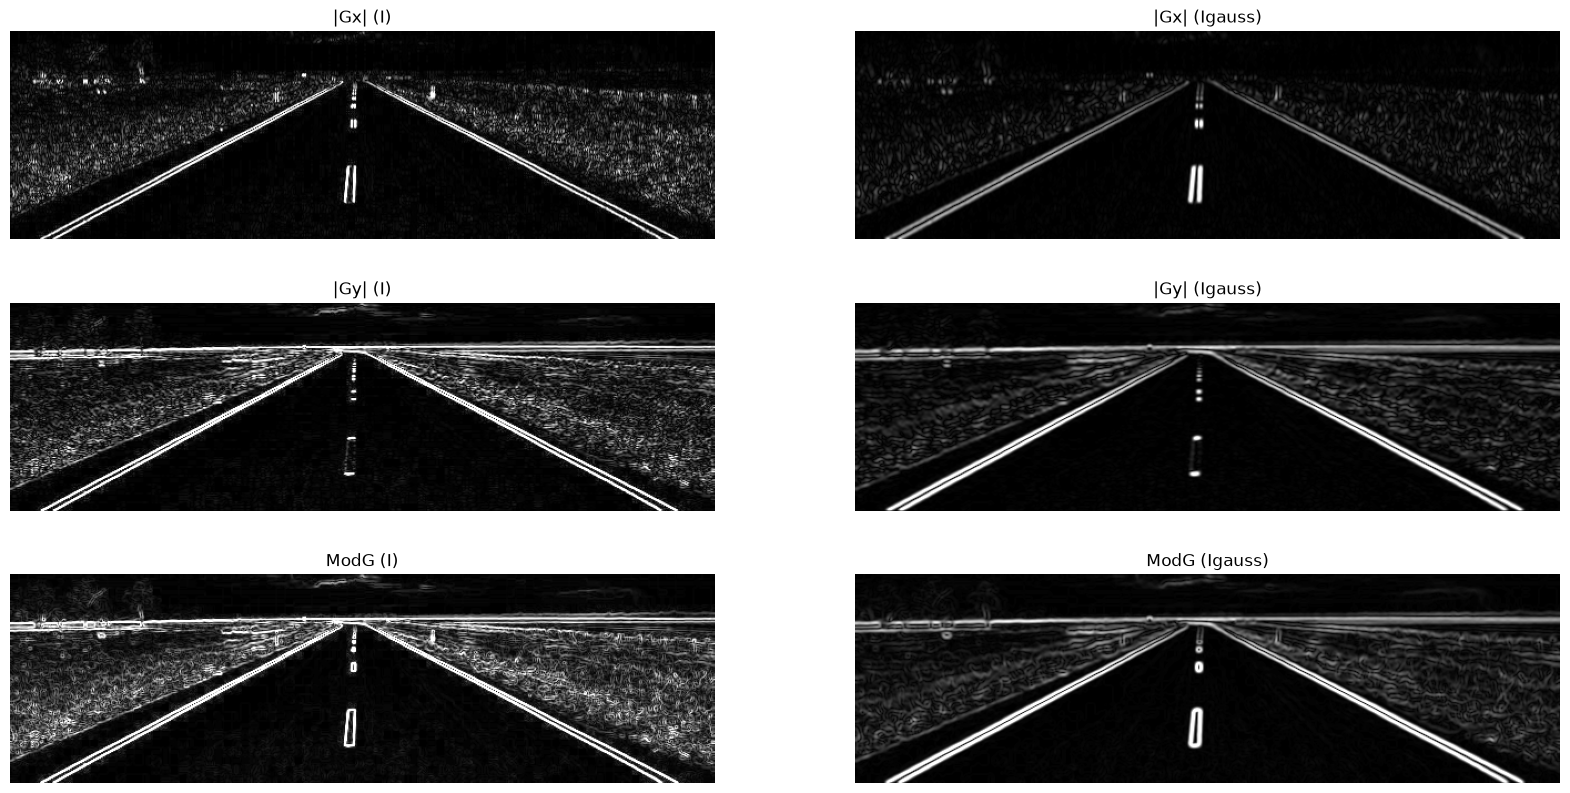

In [21]:
plt.figure(figsize=(20,10))
for i in range(6):
    plt.subplot(3, 2, i + 1)
    plt.imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    plt.title(titulos[i])
    plt.axis("off")
plt.show()

6. Utilizando como umbrales el 10, 25, 50 y 75% del valor máximo de la matriz magnitud del
vector gradiente obtenida para la imagen de intensidad I, representar las imágenes binarias
de bordes de I e Igauss resultado de la aplicación del detector de bordes de Sobel.

**Organización de las gráficas:**

Se debe utilizar la misma estructura del apartado anterior para representar las imágenes
binarias de I e Igauss con los umbrales establecidos (columna de la izquierda para
mostrar las binarizaciones de I, columna de la derecha para las de Igauss)

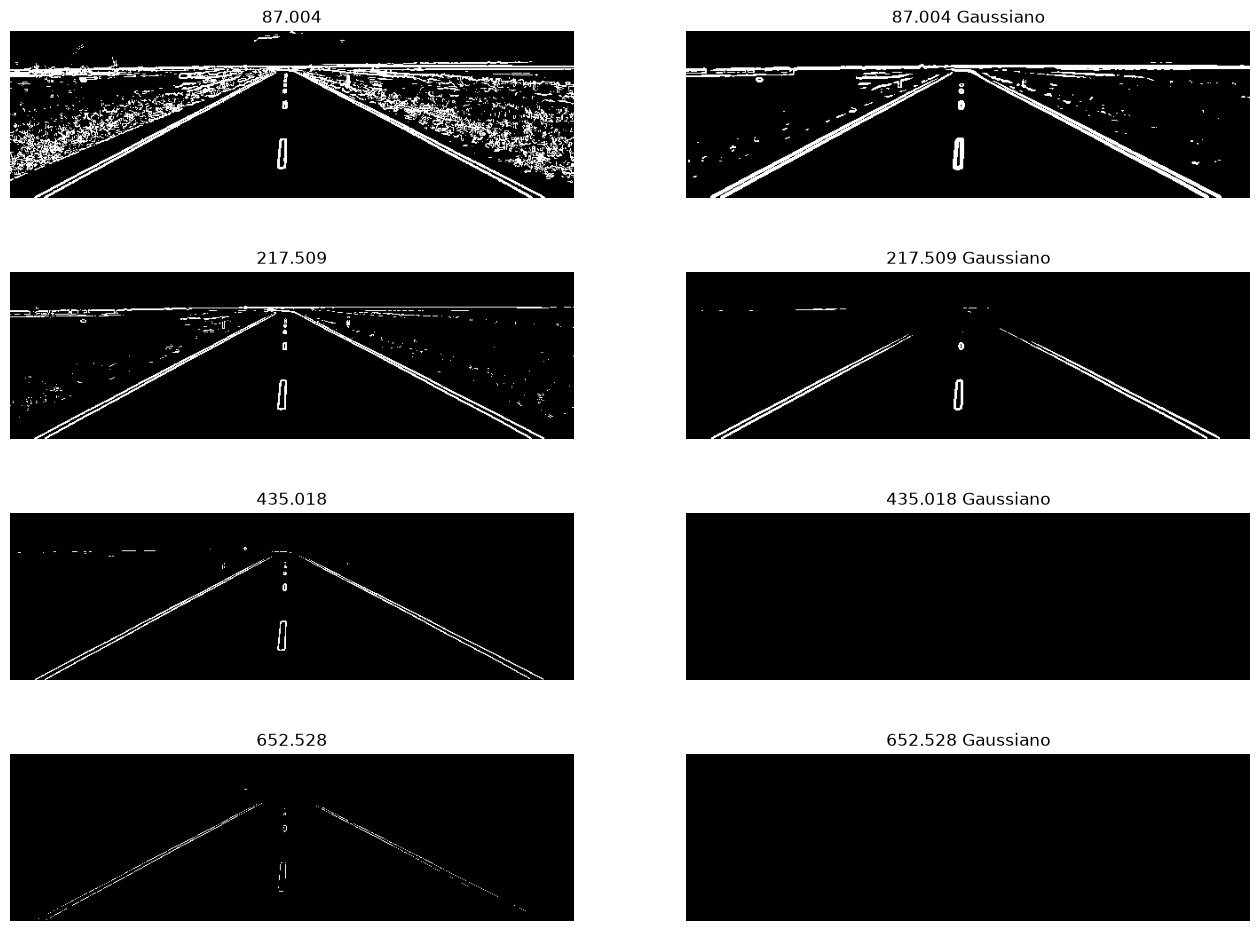

In [32]:
Ks = [0.1, 0.25, 0.5, 0.75]

umbrales = [k * maximoGradiente for k in Ks]

binarias = [ModG > umb for umb in umbrales]
binariasGauss = [ModGg > umb for umb in umbrales]

plt.figure(figsize=(16,12))

for i in range(len(umbrales)):
    for j in range(1,3):
        plt.subplot(4, 2, 2 * i + j)
        titulo = f"{umbrales[i]:.3f}"
        imagen = binarias[i]
        if j == 2:
            titulo += " Gaussiano"
            imagen = binariasGauss[i]
        plt.imshow(imagen, cmap="gray")
        plt.title(titulo)
        plt.axis("off")
plt.show()


7. Adelgazamiento de bordes.

Utilizando la función facilitada

`MagGradSnM = aplicar_supresion_no_maxima(Gx, Gy, MagGrad)`

-  Aplica el algoritmo de supresión no máxima a la magnitud del gradiente de la imagen
suavizada, Igauss.

-  Visualiza como imágenes las magnitudes del gradiente de entrada y salida del
algoritmo (1 ventana, dos imágenes distribuidas en 2 filas y 1 columna).

- Utilizando como umbrales el 10, 25, 50 y 75% del valor máximo de la matriz magnitud
del vector gradiente obtenida para la imagen de intensidad suavizada Igauss, binariza
ambas magnitudes del gradiente y muestra los resultados como imágenes (1 ventana, 4
filas y 2 columnas de imágenes; las filas se corresponden con los umbrales y las
columnas con el tipo de magnitud de gradiente que se está binarizando).

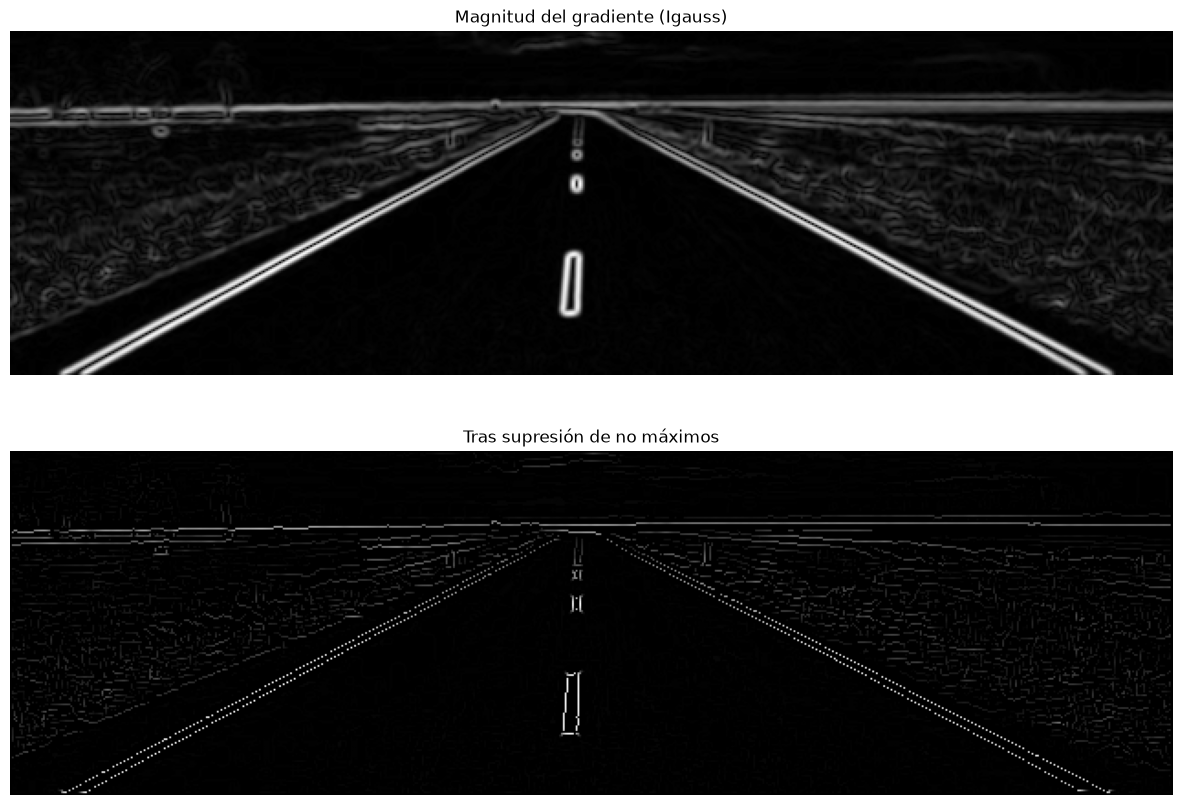

In [36]:
from FUNCIONES.funcion_aplicar_supresion_no_maxima import aplicar_supresion_no_maxima

MagGradSnM = aplicar_supresion_no_maxima(Gxg, Gyg, ModGg)

plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
plt.imshow(ModGg, cmap="gray", vmin=0, vmax=ModGg.max())
plt.title("Magnitud del gradiente (Igauss)")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(MagGradSnM, cmap="gray", vmin=0, vmax=ModGg.max())
plt.title("Tras supresión de no máximos")
plt.axis("off")

plt.show()

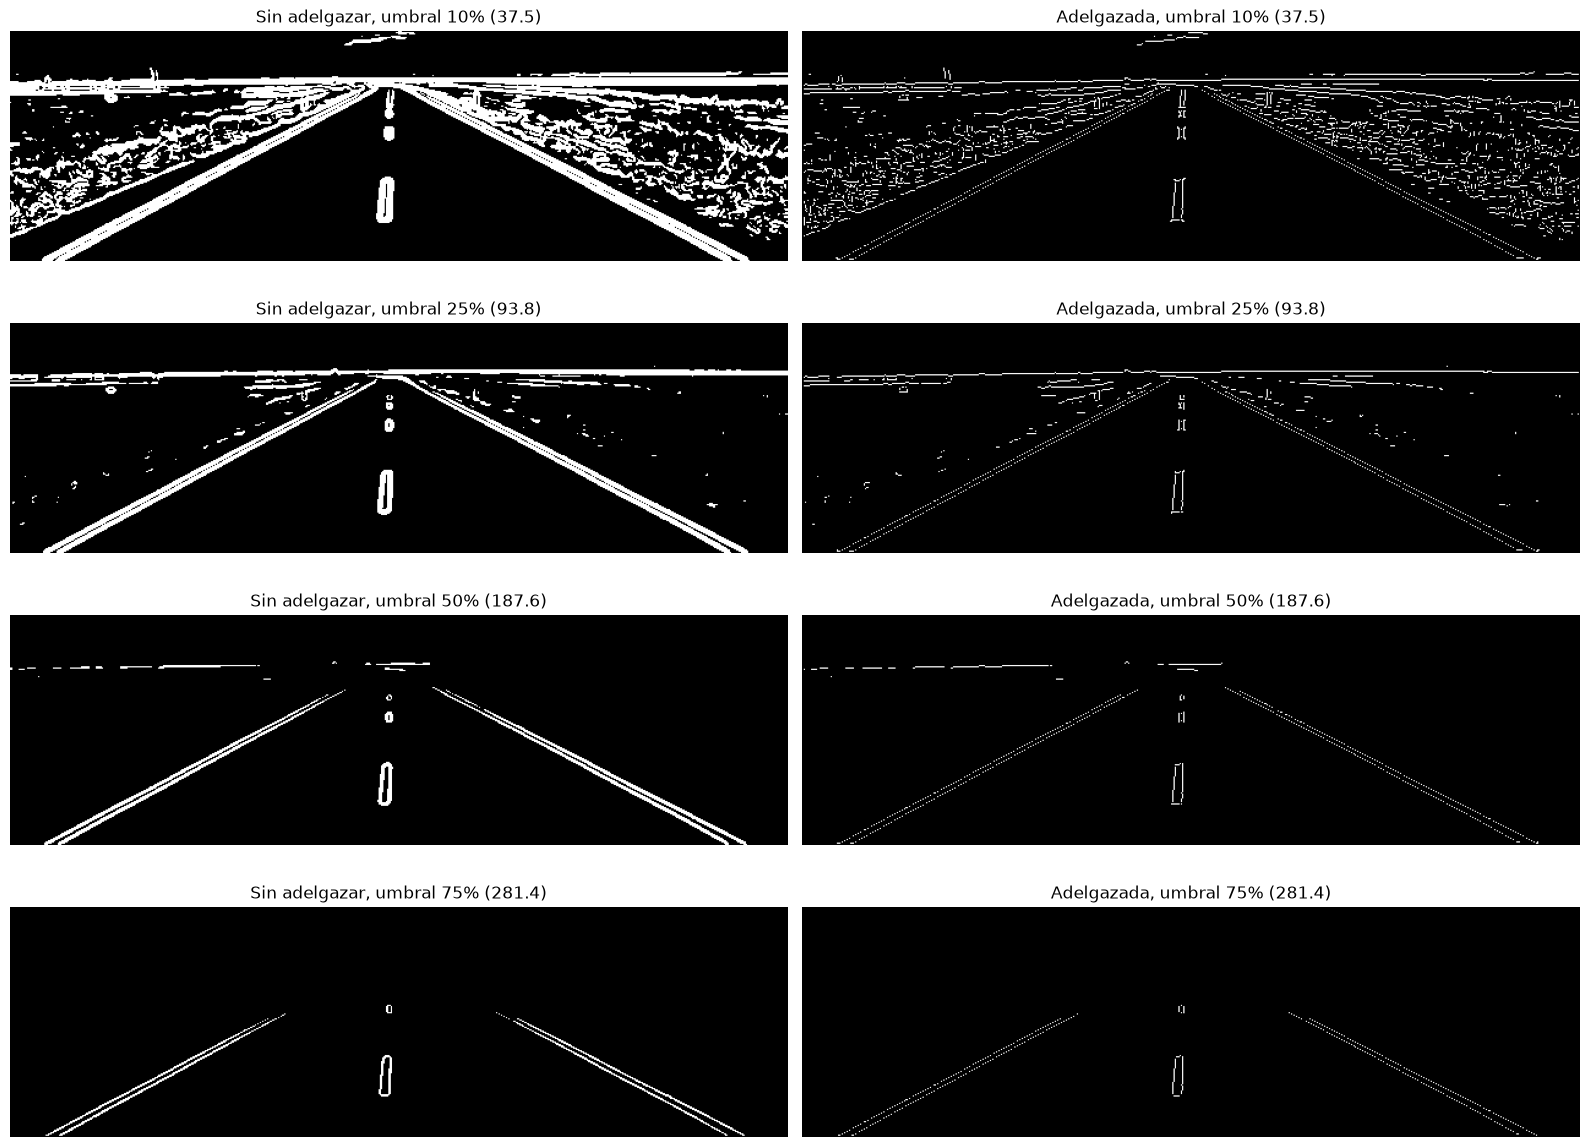

In [40]:
Ks = [0.10, 0.25, 0.50, 0.75]
maximo = ModGg.max()
umbrales = [k * maximo for k in Ks]

plt.figure(figsize=(16, 12))
for i, (k, u) in enumerate(zip(Ks, umbrales)):
    plt.subplot(4, 2, 2 * i + 1)
    plt.imshow(ModGg > u, cmap="gray")
    plt.title(f"Sin adelgazar, umbral {int(k*100)}% ({u:.1f})")
    plt.axis("off")

    plt.subplot(4, 2, 2 * i + 2)
    plt.imshow(MagGradSnM > u, cmap="gray")
    plt.title(f"Adelgazada, umbral {int(k*100)}% ({u:.1f})")
    plt.axis("off")

plt.tight_layout()
plt.show()

**Objetivos teóricos:**

- Fundamentos de las etapas metodológicas de un detector de bordes basados en primera
derivada. Análisis de la información de la magnitud del vector gradiente y de sus
componentes y su posterior binarización.

- Fundamentos de algoritmo de adelgazamiento de bordes basado en supresión no
máxima y su integración en un detector de bordes basado en primera derivada.

## TERCERA PARTE: Detección de bordes con OpenCV

8. Detector de bordes basados en primera derivada: Sobel

a. Aplica las funciones de OpenCV Sobel y magnitude para calcular las componentes del
vector gradiente Gx, Gy y su magnitud de la imagen I.

In [41]:
Gx = cv2.Sobel(I, cv2.CV_64F, 1, 0, ksize=3, borderType=cv2.BORDER_REPLICATE)
Gy = cv2.Sobel(I, cv2.CV_64F, 0, 1, ksize=3, borderType=cv2.BORDER_REPLICATE)

ModG = cv2.magnitude(Gx, Gy)

b. Genera una imagen de bordes mediante el umbral obtenido mediante el método de
Otsu:

- Utiliza la función cv2.threshold para obtener una imagen de bordes utilizando como
umbral el obtenido mediante el método de Otsu. 

- Para aplicar el método de Otsu en la binarización, la función cv2.threshold debe
recibir como entrada la magnitud del gradiente en formato uint8 con sus valores
escalados a 0-255 (utiliza para ello la función normalize con la opción cv2.CV_8U)
y configurarla para que aplique el umbral que genera el método de Otsu
(cv2.THRESH_BINARY + cv2.THRESH_OTSU).

**Observación:**la opción cv2.CV_8U en normalize permite redondear los valores al entero más
cercano. La opción de utilizar astype(np.uint8) a la salida de normalize (sin cv2.CV_8U) trunca los
valores decimales y siempre ajuste al entero más bajo.

- La función devuelve el umbral utilizado y la imagen de bordes en uint8. Llamemos
a este valor de umbral umbralOtsu.

Umbral de Otsu: 71.0


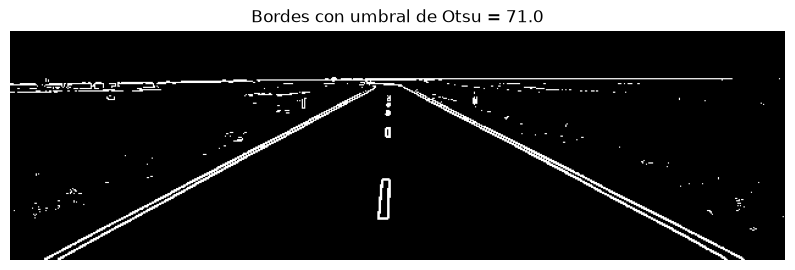

In [42]:
ModG8 = cv2.normalize(ModG, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)

umbralOtsu, bordesOtsu = cv2.threshold(ModG8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Umbral de Otsu:", umbralOtsu)

plt.figure(figsize=(10, 5))
plt.imshow(bordesOtsu, cmap="gray", vmin=0, vmax=255)
plt.title(f"Bordes con umbral de Otsu = {umbralOtsu:.1f}")
plt.axis("off")
plt.show()

c. Utilizando la función threshold, genera una imagen de bordes aplicando un umbral de
valor 0.4*umbralOtsu.

Umbral de Otsu: 71.0  ->  umbral bajo (0.4·Otsu): 28.4


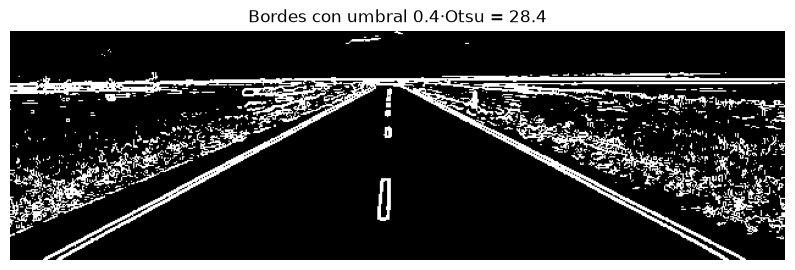

In [43]:
umbralBajo = 0.4 * umbralOtsu

_, bordesUmbralBajo = cv2.threshold(ModG8, umbralBajo, 255, cv2.THRESH_BINARY)

print(f"Umbral de Otsu: {umbralOtsu:.1f}  ->  umbral bajo (0.4·Otsu): {umbralBajo:.1f}")

plt.figure(figsize=(10, 5))
plt.imshow(bordesUmbralBajo, cmap="gray", vmin=0, vmax=255)
plt.title(f"Bordes con umbral 0.4·Otsu = {umbralBajo:.1f}")
plt.axis("off")
plt.show()

c. Visualiza las dos imágenes de bordes obtenidas (1 ventana, 2 imágenes distribuidas en 2 filas y 1 columna, en las que aparezca en el título el valor del umbral utilizado)

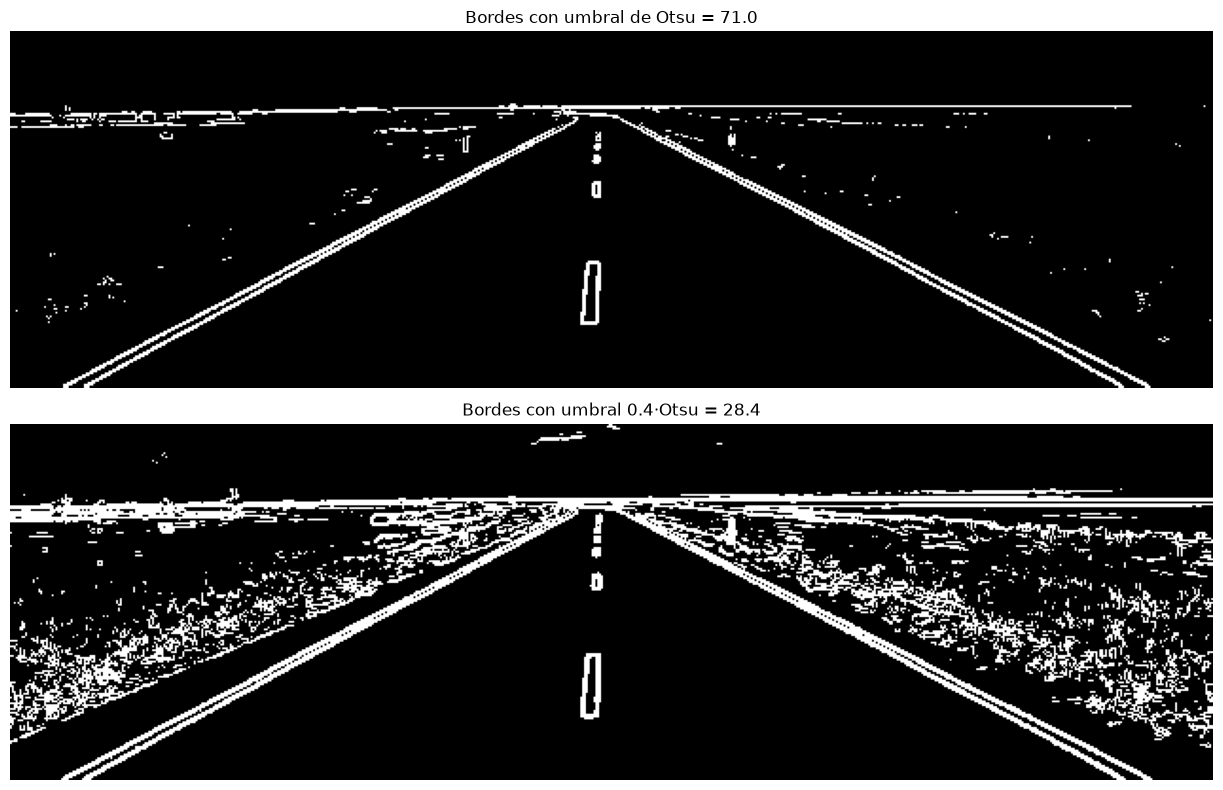

In [45]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 1, 1)
plt.imshow(bordesOtsu, cmap="gray", vmin=0, vmax=255)
plt.title(f"Bordes con umbral de Otsu = {umbralOtsu:.1f}")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(bordesUmbralBajo, cmap="gray", vmin=0, vmax=255)
plt.title(f"Bordes con umbral 0.4·Otsu = {umbralBajo:.1f}")
plt.axis("off")

plt.tight_layout()
plt.show()

**Objetivos teóricos:**

- Implementación de detector de bordes representativo basado en primera derivada en
OpenCV.

- Aplicación y comprensión de todos los parámetros de entrada y salida de la función
threshold para la etapa final de binarización: uso de umbral manual y generación de
umbral de forma automática mediante el método de Otsu

9. Detector de bordes basados en primera derivada: Canny

a. Utilizando la función de OpenCV Canny, aplica sobre la imagen de intensidad I un
detector de bordes Canny con umbrales superior e inferior: umbralMayor = 100 y
umbralMenor = 0.4*umbralMayor. Aplica nuevamente el detector con la pareja de
umbrales umbralMayor = 700 y umbralMenor = 0.4*umbralMayor.

In [49]:
umbralMayor1 = 100
umbralMenor1 = 0.4 * umbralMayor1
bordesCanny1 = cv2.Canny(I, umbralMenor1, umbralMayor1)

umbralMayor2 = 700
umbralMenor2 = 0.4 * umbralMayor2
bordesCanny2 = cv2.Canny(I, umbralMenor2, umbralMayor2)

b. Visualiza las dos imágenes de bordes obtenidas (1 ventana, 2 imágenes distribuidas en
2 filas y 1 columna, en las que aparezca en el título el valor del umbral utilizado) y
justifica los resultados.


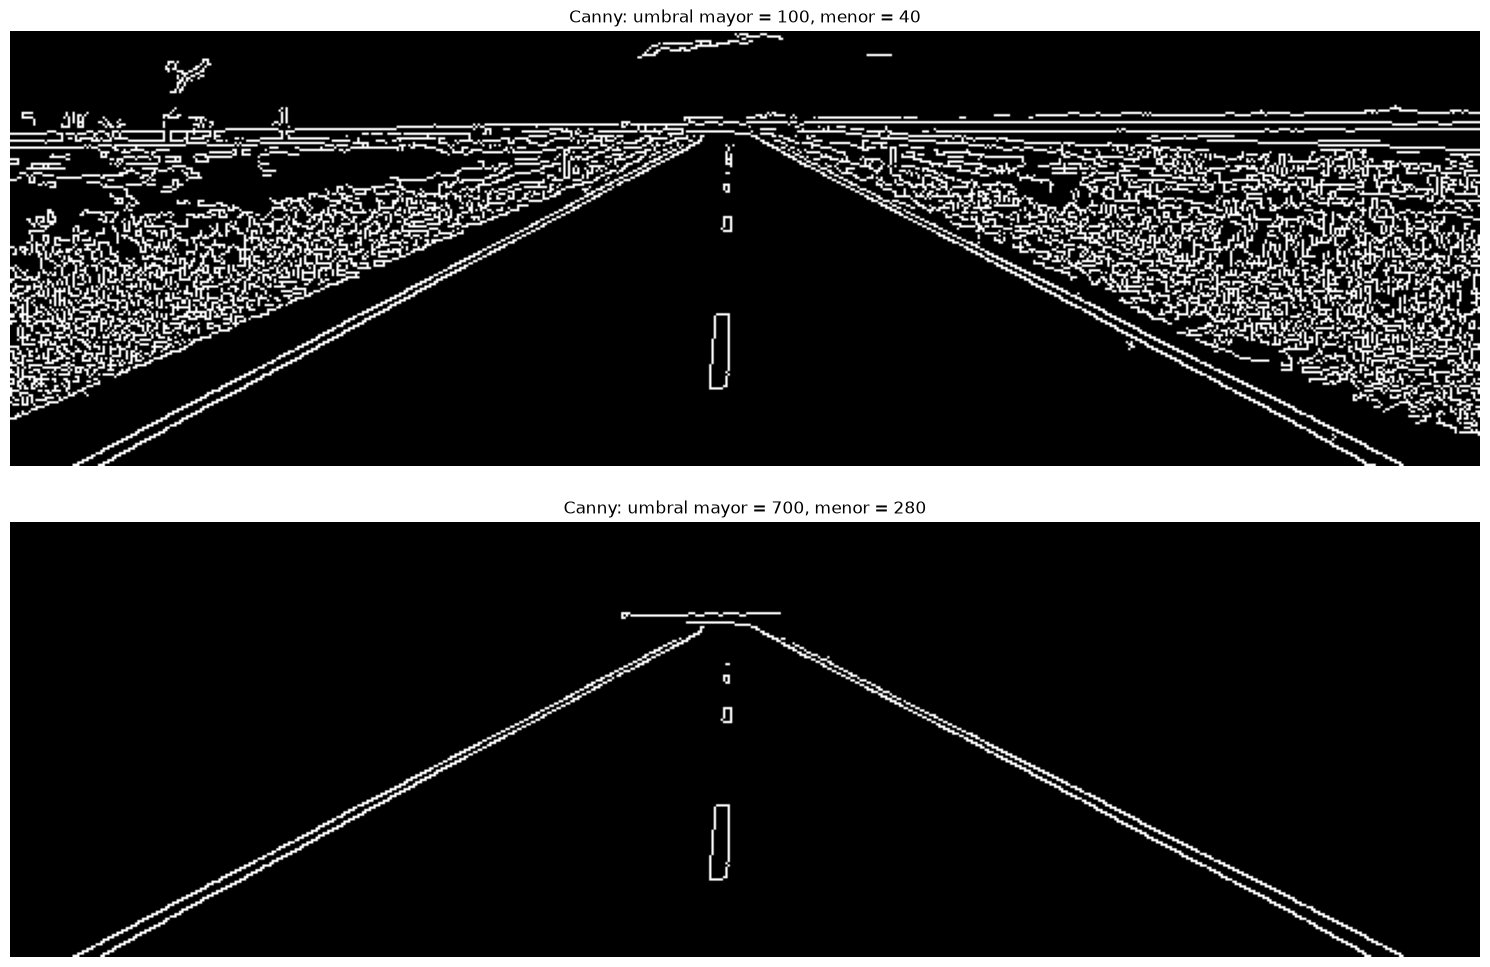

In [50]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
plt.imshow(bordesCanny1, cmap="gray", vmin=0, vmax=255)
plt.title(f"Canny: umbral mayor = {umbralMayor1}, menor = {umbralMenor1:.0f}")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(bordesCanny2, cmap="gray", vmin=0, vmax=255)
plt.title(f"Canny: umbral mayor = {umbralMayor2}, menor = {umbralMenor2:.0f}")
plt.axis("off")

plt.tight_layout()
plt.show()

c. Teniendo en cuenta las siguientes observaciones, resume los distintos pasos procedimentales (interpretando las entradas-salidas de cada paso) que aplica el detector de bordes de Canny para, a partir de una imagen de intensidad, obtener su imagen binaria de bordes

**Observaciones**: 

- El detector de Canny en OpenCV aplica internamente un suavizado Gaussiano 5×5 con σ = 1.4. En el
artículo de John Canny (1986) se define que el suavizado previo debe hacerse con una Gaussiana de
desviación estándar σ, y se sugiere: “A good practical value for σ is between 1.0 and 2.0; I found σ =
1.4 works well for most images.”

- OpenCV usa el operador Sobel para calcular las componentes del vector de gradiente.

Canny convierte una imagen de intensidad en una imagen binaria de bordes de 1 píxel de grosor, conectados y con poco ruido. Cada paso usa la salida del anterior.

#### 1. Suavizado
- Entrada: la imagen de intensidad I (N×M, uint8).
- Operación: convolución con una gaussiana de 5×5 y σ = 1.4, según la observación del enunciado.
- Salida: una imagen suavizada Is, del mismo tamaño, con menos ruido.
- Para qué: las derivadas amplifican el ruido, y sin este paso la textura del césped se detectaría como bordes. El precio es que los bordes reales se desenfocan algo.

#### 2. Cálculo del gradiente (Sobel)
- Entrada: Is.
- Operación: convolución con las máscaras de Sobel para obtener Gx y Gy.
- **Salida**:
    - La magnitud |G| = √(Gx² + Gy²), o |Gx| + |Gy| en la configuración por defecto de OpenCV. Indica cuánto cambia la intensidad.
    - La dirección θ = arctan2(Gy, Gx), que apunta de oscuro a claro y es perpendicular al borde.
- Resultado: bandas anchas de varios píxeles alrededor de cada borde.

#### 3. Supresión de no máximos
- Entrada: la magnitud |G| y la dirección θ.
- Operación: θ se cuantiza en cuatro direcciones (0°, 45°, 90°, 135°). Cada píxel se compara con sus dos vecinos en la dirección del gradiente, y si no es el máximo local se pone a 0.
- Salida: una magnitud adelgazada, con líneas de 1 píxel en la cresta de cada banda.
- Para qué: mejora la localización del borde, de modo que cada borde real queda representado por una sola línea.

#### 4. Umbralización por histéresis
- Entrada: la magnitud adelgazada y dos umbrales, umbralMenor y umbralMayor.
- Operación: cada píxel se clasifica según su magnitud.
    - Mayor que umbralMayor: borde fuerte, siempre se conserva.
    - Menor que umbralMenor: descartado.
    - Entre ambos: borde débil, que se conserva solo si está conectado, directa o indirectamente, a un borde fuerte.    
- Salida: la imagen binaria final, con 255 en los bordes y 0 en el resto.
- Para qué: un único umbral obliga a elegir entre ruido y bordes rotos, y con dos umbrales se recuperan los tramos débiles de una línea sin traer los fragmentos de ruido aislados.

10. Postprocesado de imagen binaria de bordes de Canny. Aplica los siguientes pasos
para generar una detección de bordes de la carretera:

-  Aplica sobre la imagen de intensidad I un detector de bordes Canny con umbrales
superior e inferior umbralMayor = 700 y umbralMenor = 0.4*umbralMayor.
